# Module 1B: Multi-Architecture Time-Series Benchmark on Energy Regimes

In [`01_demand_forecasting.ipynb`](01_demand_forecasting.ipynb) we compared Chronos-Bolt and Chronos-2 against naive baselines on Swiss electricity demand.
Here we test **whether zero-shot foundation models still win across diverse model families, stronger ML baselines, and a much harder energy regime**.

**What we compare**

- **Two contrasting 2019 day-ahead regimes (365 days × 24 h, 2,048 h context):**
  1. **Swiss electricity demand** (`CH_load_actual_entsoe_transparency`): smooth daily, weekly and heating-driven cycles.
  2. **German solar PV generation** (`DE_solar_generation_actual`): intermittent, strictly zero at night, and driven by solar irradiance.
     *(Note: we use German rather than Swiss PV here because ENTSO-E Swiss PV reporting has a 3× step-change across 2017–2020.)*
- **Seven model families:** naive persistence (`Last week`), trained `Ridge` and `LightGBM` (with calendar, lags and weather),
  `Chronos-Bolt` (T5 encoder-decoder), `Chronos-2` (with and without weather covariates), Google `TimesFM 2.5` (decoder-only patch Transformer),
  and NX-AI `TiRex` (xLSTM recurrent).
- **Energy-domain metrics & operational cost:** Peak-5% MAE, Ramp MAE, 80% coverage, Winkler score, 3-quantile CRPS,
  stylized hourly imbalance cost (EUR), peak GPU VRAM, latency and GPU energy (Joules).

**Prerequisites:** install the optional Phase 2 extras (`pip install -r requirements-extras/tsfm.txt`).

## 0. Setup, GPU check and profiler

In [1]:
import gc
import logging
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers

transformers.utils.logging.disable_progress_bar()
transformers.utils.logging.set_verbosity_error()
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from fm4ues import (
    RunProfiler,
    crps_from_quantiles,
    inspect_model,
    interval_coverage,
    mae,
    mape,
    peak_hour_mae,
    print_hardware_banner,
    ramp_rate_mae,
    stylized_imbalance_cost,
    winkler_score,
)

CACHE = ROOT / "data" / "cache"
CACHE.mkdir(parents=True, exist_ok=True)
IMG_DIR = ROOT / "docs" / "assets" / "img"
IMG_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() and torch.cuda.device_count() > 0 else "cpu"
print_hardware_banner(DEVICE, CACHE, ROOT)

np.random.seed(0)
torch.manual_seed(0)

profiler = RunProfiler(
    module="module1_timeseries",
    notebook="02_tsfm_benchmark_energy",
    device=DEVICE,
    cache_dir=CACHE,
    results_dir=ROOT / "benchmarks" / "results",
)
profiler.start_run()

plt.rcParams["figure.figsize"] = (12, 4)

Python   : 3.11.18 | OS: Windows 10 | RAM: 617 GB
PyTorch  : 2.11.0+cu128
Device   : cuda (Quadro RTX 6000, 25.8 GB VRAM, SM 7.5, TDP 260 W, native fp16, emulated bf16)
Telemetry: NVML GPU power (50 ms) + CodeCarbon offline (system)
Data dir : data\cache


## 1. Load Load & Solar PV datasets with weather covariates

Both electricity series come from the same Open Power System Data (OPSD) file. Weather comes from the Open-Meteo Historical API
(5 Swiss cities for Load; 5 German cities for Solar PV) and is cached locally after the first download.

In [2]:
import requests

OPSD_URL = "https://data.open-power-system-data.org/time_series/2020-10-06/time_series_60min_singleindex.csv"
CH_LOAD_FILE = CACHE / "opsd_ch_load.csv"
DE_SOLAR_FILE = CACHE / "opsd_de_solar.csv"
CH_WEATHER_FILE = CACHE / "openmeteo_ch_weather.csv"
DE_WEATHER_FILE = CACHE / "openmeteo_de_weather.csv"

CH_CITIES = {
    "Zurich": (47.37, 8.54), "Geneva": (46.20, 6.14), "Basel": (47.56, 7.59),
    "Bern": (46.95, 7.45), "Lugano": (46.01, 8.96),
}
DE_CITIES = {
    "Berlin": (52.52, 13.40), "Munich": (48.14, 11.58), "Hamburg": (53.55, 9.99),
    "Cologne": (50.94, 6.96), "Frankfurt": (50.11, 8.68),
}

def load_weather(path, cities):
    if not path.exists():
        params = {
            "latitude": ",".join(str(lat) for lat, _ in cities.values()),
            "longitude": ",".join(str(lon) for _, lon in cities.values()),
            "start_date": "2016-01-01", "end_date": "2020-09-30",
            "hourly": "temperature_2m,shortwave_radiation", "timezone": "UTC",
        }
        resp = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=120)
        resp.raise_for_status()
        per_city = [pd.DataFrame(loc["hourly"]).set_index("time") for loc in resp.json()]
        (sum(per_city) / len(per_city)).to_csv(path)
    w = pd.read_csv(path, index_col="time", parse_dates=["time"])
    w.columns = ["temperature", "radiation"]
    return w

with profiler.step("1. Load OPSD load/solar and Open-Meteo weather"):
    if not CH_LOAD_FILE.exists():
        pd.read_csv(OPSD_URL, usecols=["utc_timestamp", "CH_load_actual_entsoe_transparency"]).to_csv(CH_LOAD_FILE, index=False)
    if not DE_SOLAR_FILE.exists():
        pd.read_csv(OPSD_URL, usecols=["utc_timestamp", "DE_solar_generation_actual"]).to_csv(DE_SOLAR_FILE, index=False)

    ch_load = pd.read_csv(CH_LOAD_FILE, index_col="utc_timestamp")["CH_load_actual_entsoe_transparency"].rename("target")
    ch_load.index = pd.to_datetime(ch_load.index, utc=True).tz_localize(None)
    ch_load = ch_load.loc["2016-01-01":"2020-09-30"].asfreq("h").interpolate(limit=6)

    de_solar = pd.read_csv(DE_SOLAR_FILE, index_col="utc_timestamp")["DE_solar_generation_actual"].rename("target")
    de_solar.index = pd.to_datetime(de_solar.index, utc=True).tz_localize(None)
    de_solar = de_solar.loc["2017-01-01":"2020-09-30"].asfreq("h").interpolate(limit=6)

    ch_weather = load_weather(CH_WEATHER_FILE, CH_CITIES).reindex(ch_load.index).interpolate(limit=6)
    de_weather = load_weather(DE_WEATHER_FILE, DE_CITIES).reindex(de_solar.index).interpolate(limit=6)

    df_load = pd.concat([ch_load, ch_weather], axis=1)
    df_solar = pd.concat([de_solar, de_weather], axis=1)

assert not df_load.isna().any().any() and not df_solar.isna().any().any()
print(f"Swiss Load : {len(df_load):,} h ({df_load.index.min():%Y-%m-%d} to {df_load.index.max():%Y-%m-%d}), mean {df_load['target'].mean():,.0f} MW")
print(f"German PV  : {len(df_solar):,} h ({df_solar.index.min():%Y-%m-%d} to {df_solar.index.max():%Y-%m-%d}), mean {df_solar['target'].mean():,.0f} MW, max {df_solar['target'].max():,.0f} MW")

[profile] 1. Load OPSD load/solar and Open-Meteo weather: 10.4 s | GPU 43 W (445.5 J)
Swiss Load : 41,640 h (2016-01-01 to 2020-09-30), mean 6,760 MW
German PV  : 32,856 h (2017-01-01 to 2020-09-30), mean 4,885 MW, max 32,947 MW


## 2. Forecast set-up & leak-free ML feature engineering

For both regimes we evaluate all **365 day-ahead forecasts of 2019** (horizon = 24 h, context = 2,048 h).
For our trained ML baselines (`Ridge` and `LightGBM`), every feature used for hour $t$ of forecast day $d$ must be available at midnight UTC of day $d$:

- Calendar position of $t$: `hour`, `dayofweek`, `dayofyear` (sin/cos encoded), `is_weekend`.
- Same-hour historical lags known before midnight $d$: `lag_24`, `lag_48`, `lag_168` (24 h, 48 h, 7 days earlier).
- Previous completed day & week summaries (`prev_day_mean`, `prev_day_std`, `prev_week_mean`) shifted by 1 full day.
- Exogenous weather (`temperature`, `radiation`) plus yesterday's weather (`temp_lag24`, `rad_lag24`).

In [3]:
CONTEXT = 2048
HORIZON = 24
QUANTILES = [0.1, 0.5, 0.9]
ORIGINS = pd.date_range("2019-01-01", "2019-12-31", freq="D")

def prepare_regime(df_reg):
    y = df_reg["target"]
    pos = {t: i for i, t in enumerate(y.index)}
    actual = np.stack([y.values[pos[o]:pos[o] + HORIZON] for o in ORIGINS])
    contexts = np.stack([y.values[pos[o] - CONTEXT:pos[o]] for o in ORIGINS])
    return {"df": df_reg, "y": y, "pos": pos, "actual": actual, "contexts": contexts}

regimes = {
    "Load": prepare_regime(df_load),
    "Solar": prepare_regime(df_solar),
}

def make_ml_features(df_reg):
    feat = pd.DataFrame(index=df_reg.index)
    idx = df_reg.index
    feat["hour_sin"] = np.sin(2 * np.pi * idx.hour / 24.0)
    feat["hour_cos"] = np.cos(2 * np.pi * idx.hour / 24.0)
    feat["dow_sin"] = np.sin(2 * np.pi * idx.dayofweek / 7.0)
    feat["dow_cos"] = np.cos(2 * np.pi * idx.dayofweek / 7.0)
    feat["doy_sin"] = np.sin(2 * np.pi * idx.dayofyear / 365.25)
    feat["doy_cos"] = np.cos(2 * np.pi * idx.dayofyear / 365.25)
    feat["is_weekend"] = (idx.dayofweek >= 5).astype(float)

    y = df_reg["target"]
    feat["lag_24"] = y.shift(24)
    feat["lag_48"] = y.shift(48)
    feat["lag_168"] = y.shift(168)

    daily = y.resample("D").agg(["mean", "std"]).shift(1)
    daily_week = y.resample("D").mean().rolling(7).mean().shift(1)
    day_key = idx.normalize()
    feat["prev_day_mean"] = day_key.map(daily["mean"])
    feat["prev_day_std"] = day_key.map(daily["std"])
    feat["prev_week_mean"] = day_key.map(daily_week)

    feat["temperature"] = df_reg["temperature"]
    feat["radiation"] = df_reg["radiation"]
    feat["temp_lag24"] = df_reg["temperature"].shift(24)
    feat["rad_lag24"] = df_reg["radiation"].shift(24)
    feat["target"] = y
    return feat.dropna()

preds = {"Load": {}, "Solar": {}}
quants = {"Load": {}, "Solar": {}}

with profiler.step("2. Baselines (Last week, Ridge, LightGBM) on Load + Solar", n_items=len(ORIGINS) * 2, item_unit="day"):
    from sklearn.linear_model import Ridge
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline
    import lightgbm as lgb

    for rname, reg in regimes.items():
        y, pos = reg["y"], reg["pos"]
        preds[rname]["Last week"] = np.stack([y.values[pos[o] - 168:pos[o] - 168 + HORIZON] for o in ORIGINS])

        ml_df = make_ml_features(reg["df"])
        feat_cols = [c for c in ml_df.columns if c != "target"]
        train_df = ml_df.loc[:"2018-12-31 23:00"]
        test_df = ml_df.loc["2019-01-01":"2019-12-31 23:00"]
        assert len(test_df) == len(ORIGINS) * HORIZON

        ridge = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(train_df[feat_cols], train_df["target"])
        preds[rname]["Ridge (+ weather & lags)"] = ridge.predict(test_df[feat_cols]).reshape(len(ORIGINS), HORIZON)

        lgb_q = {}
        for alpha in QUANTILES:
            gbm = lgb.LGBMRegressor(
                objective="quantile",
                alpha=alpha,
                n_estimators=400,
                learning_rate=0.05,
                num_leaves=63,
                random_state=0,
                n_jobs=-1,
                verbosity=-1,
            )
            gbm.fit(train_df[feat_cols], train_df["target"])
            lgb_q[alpha] = gbm.predict(test_df[feat_cols]).reshape(len(ORIGINS), HORIZON)
        preds[rname]["LightGBM (+ weather & lags)"] = lgb_q[0.5]
        quants[rname]["LightGBM (+ weather & lags)"] = (lgb_q[0.1], lgb_q[0.9])

profiler.register_model(inspect_model(None, name="Ridge (+ weather & lags)", family="Linear + lags", modality="Tabularized time series", source="scikit-learn", license="BSD-3-Clause", limits="Needs historical training split"), cpu_viable=True)
profiler.register_model(inspect_model(None, name="LightGBM (+ weather & lags)", family="Gradient-boosted trees", modality="Tabularized time series", source="lightgbm", license="MIT", limits="Needs historical training split"), cpu_viable=True)
print("Trained baselines ready for Load and Solar.")

[profile] 2. Baselines (Last week, Ridge, LightGBM) on Load + Solar: 108.4 s | GPU 24 W (2594.0 J) | 148.54 ms/day
Trained baselines ready for Load and Solar.


## 3. Run all time-series foundation models (isolated GPU memory per family)

Each model family is loaded, evaluated on **Swiss Load** and **German Solar PV**, registered in `RunProfiler`,
and freed from GPU VRAM before loading the next model so peak VRAM and GPU energy stay cleanly isolated.

In [4]:
# --- 3A. Chronos-Bolt (base): T5 encoder-decoder, univariate --------------
from chronos import BaseChronosPipeline

with profiler.step("3. Load Chronos-Bolt (base)", model_name="Chronos-Bolt (base)"):
    bolt = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-base", device_map=DEVICE, torch_dtype=torch.float32)

profiler.register_model(inspect_model(
    bolt, name="Chronos-Bolt (base)", family="T5 encoder-decoder", modality="Time series (univariate)",
    source="amazon/chronos-bolt-base", license="Apache-2.0", limits="Context <= 2,048, univariate",
    hf_repo_id="amazon/chronos-bolt-base",
))

for rname, reg in regimes.items():
    with profiler.step(f"4. Chronos-Bolt: {rname} 365 days", n_items=len(ORIGINS), item_unit="day", model_name="Chronos-Bolt (base)"):
        q, _ = bolt.predict_quantiles(torch.tensor(reg["contexts"], dtype=torch.float32), prediction_length=HORIZON, quantile_levels=QUANTILES)
    q = q.numpy()
    preds[rname]["Chronos-Bolt (base)"] = q[..., 1]
    quants[rname]["Chronos-Bolt (base)"] = (q[..., 0], q[..., 2])

del bolt; gc.collect()
if DEVICE == "cuda": torch.cuda.empty_cache()

[profile] 3. Load Chronos-Bolt (base): 2.4 s | VRAM 0.82 GB | GPU 24 W (56.7 J)


[profile] 4. Chronos-Bolt: Load 365 days: 1.5 s | VRAM 4.92 GB | GPU 143 W (216.3 J) | 4.14 ms/day


[profile] 4. Chronos-Bolt: Solar 365 days: 0.9 s | VRAM 4.92 GB | GPU 257 W (225.0 J) | 2.40 ms/day


In [5]:
# --- 3B. Chronos-2: Time-series Transformer with & without covariates ---
from chronos import Chronos2Pipeline

def run_chronos2(pipe, df_reg, pos, with_weather):
    cols = ["target", "temperature", "radiation"] if with_weather else ["target"]
    ctx_parts, fut_parts = [], []
    for k, o in enumerate(ORIGINS):
        hist = df_reg.iloc[pos[o] - CONTEXT:pos[o]][cols].reset_index(names="timestamp")
        hist.insert(0, "id", k)
        ctx_parts.append(hist)
        if with_weather:
            fut = df_reg.iloc[pos[o]:pos[o] + HORIZON][["temperature", "radiation"]].reset_index(names="timestamp")
            fut.insert(0, "id", k)
            fut_parts.append(fut)
    ctx = pd.concat(ctx_parts, ignore_index=True)
    fut = pd.concat(fut_parts, ignore_index=True) if with_weather else None
    pred = pipe.predict_df(
        ctx, future_df=fut, id_column="id", timestamp_column="timestamp", target="target",
        prediction_length=HORIZON, quantile_levels=QUANTILES,
    ).sort_values(["id", "timestamp"])
    get = lambda col: pred[col].to_numpy().reshape(len(ORIGINS), HORIZON)
    return get("0.5"), (get("0.1"), get("0.9"))

with profiler.step("5. Load Chronos-2", model_name="Chronos-2"):
    c2 = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map=DEVICE)

profiler.register_model(inspect_model(
    c2, name="Chronos-2", family="Time-series Transformer", modality="Time series + covariates",
    source="amazon/chronos-2", license="Apache-2.0", limits="Supports past & known-future covariates",
    hf_repo_id="amazon/chronos-2",
))

for rname, reg in regimes.items():
    with profiler.step(f"6. Chronos-2 (univariate): {rname}", n_items=len(ORIGINS), item_unit="day", model_name="Chronos-2"):
        preds[rname]["Chronos-2"], quants[rname]["Chronos-2"] = run_chronos2(c2, reg["df"], reg["pos"], with_weather=False)
    with profiler.step(f"7. Chronos-2 + weather: {rname}", n_items=len(ORIGINS), item_unit="day", model_name="Chronos-2"):
        preds[rname]["Chronos-2 + weather"], quants[rname]["Chronos-2 + weather"] = run_chronos2(c2, reg["df"], reg["pos"], with_weather=True)

del c2; gc.collect()
if DEVICE == "cuda": torch.cuda.empty_cache()

[profile] 5. Load Chronos-2: 1.4 s | VRAM 0.49 GB | GPU 74 W (102.1 J)


[profile] 6. Chronos-2 (univariate): Load: 2.1 s | VRAM 2.29 GB | GPU 170 W (356.6 J) | 5.74 ms/day


[profile] 7. Chronos-2 + weather: Load: 5.2 s | VRAM 2.31 GB | GPU 221 W (1150.7 J) | 14.18 ms/day


[profile] 6. Chronos-2 (univariate): Solar: 1.9 s | VRAM 2.29 GB | GPU 207 W (394.7 J) | 5.22 ms/day


[profile] 7. Chronos-2 + weather: Solar: 5.2 s | VRAM 2.31 GB | GPU 223 W (1165.6 J) | 14.30 ms/day


In [6]:
# --- 3C. TimesFM 2.5 (200M): decoder-only patch Transformer -------------
import timesfm

with profiler.step("8. Load TimesFM 2.5 (200M)", model_name="TimesFM 2.5 (200M)"):
    tfm = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch", torch_compile=False)
    tfm.model.to(DEVICE)
    tfm.compile(
        timesfm.ForecastConfig(
            max_context=CONTEXT,
            max_horizon=HORIZON,
            per_core_batch_size=64,
            normalize_inputs=True,
            use_continuous_quantile_head=True,
            force_flip_invariance=True,
            fix_quantile_crossing=True,
        )
    )

profiler.register_model(inspect_model(
    tfm, name="TimesFM 2.5 (200M)", family="Decoder-only patch Transformer", modality="Time series (univariate)",
    source="google/timesfm-2.5-200m-pytorch", license="Apache-2.0", limits="Univariate core; covariates via xreg",
    hf_repo_id="google/timesfm-2.5-200m-pytorch",
))

for rname, reg in regimes.items():
    inputs_list = [row.astype(np.float32) for row in reg["contexts"]]
    with profiler.step(f"9. TimesFM 2.5: {rname} 365 days", n_items=len(ORIGINS), item_unit="day", model_name="TimesFM 2.5 (200M)"):
        pt, qt = tfm.forecast(horizon=HORIZON, inputs=inputs_list)
    preds[rname]["TimesFM 2.5"] = qt[..., 5]
    quants[rname]["TimesFM 2.5"] = (qt[..., 1], qt[..., 9])

del tfm; gc.collect()
if DEVICE == "cuda": torch.cuda.empty_cache()

[profile] 8. Load TimesFM 2.5 (200M): 2.8 s | VRAM 0.93 GB | GPU 62 W (177.6 J)


[profile] 9. TimesFM 2.5: Load 365 days: 3.5 s | VRAM 2.53 GB | GPU 217 W (749.9 J) | 9.47 ms/day


[profile] 9. TimesFM 2.5: Solar 365 days: 3.4 s | VRAM 2.53 GB | GPU 232 W (790.8 J) | 9.22 ms/day


In [7]:
# --- 3D. TiRex (35M): xLSTM recurrent time-series FM --------------------
import tirex

with profiler.step("10. Load TiRex", model_name="TiRex"):
    tx = tirex.load_model("NX-AI/TiRex", device=DEVICE)

profiler.register_model(inspect_model(
    tx, name="TiRex", family="xLSTM (recurrent FM)", modality="Time series (univariate)",
    source="NX-AI/TiRex", license="NX-AI Community / Apache-2.0 (check card)", limits="Univariate, 9 deciles (0.1..0.9)",
    hf_repo_id="NX-AI/TiRex",
))

for rname, reg in regimes.items():
    ctx_t = torch.tensor(reg["contexts"], dtype=torch.float32)
    with profiler.step(f"11. TiRex: {rname} 365 days", n_items=len(ORIGINS), item_unit="day", model_name="TiRex"):
        q_tx, _ = tx.forecast(context=ctx_t, prediction_length=HORIZON, output_type="numpy", batch_size=64)
    preds[rname]["TiRex"] = q_tx[..., 4]
    quants[rname]["TiRex"] = (q_tx[..., 0], q_tx[..., 8])

del tx; gc.collect()
if DEVICE == "cuda": torch.cuda.empty_cache()

[profile] 10. Load TiRex: 0.8 s | VRAM 0.30 GB | GPU 83 W (64.5 J)


[profile] 11. TiRex: Load 365 days: 3.4 s | VRAM 0.26 GB | GPU 137 W (462.7 J) | 9.26 ms/day


[profile] 11. TiRex: Solar 365 days: 3.5 s | VRAM 0.26 GB | GPU 135 W (472.4 J) | 9.61 ms/day


## 4. Energy-domain evaluation on Load & Solar PV

We score every model with UES operational metrics:
- **Peak-5% MAE (MW)** on Load (top 5% highest-demand hours) and **Daytime MAE (MW)** on Solar PV (`actual > 100 MW`, ignoring easy zero-at-night hours).
- **Ramp MAE (MW/h)**: hour-to-hour change accuracy.
- **Raw neg. pred (%)** on Solar PV: fraction of raw predicted hours below 0 MW before physical clipping (`np.clip(..., 0, None)`). Note that TimesFM 2.5 activates `infer_is_positive=True` by default when inputs are non-negative.
- **80% coverage, Winkler score, and 3-quantile CRPS**: probabilistic calibration and sharpness.
- **Imbalance cost (kEUR/yr)**: stylized hourly balancing penalty assuming 80 EUR/MWh upward shortfall and 40 EUR/MWh downward surplus.

In [8]:
def step_lookup(model_prefix, regime_name):
    for s in profiler.steps:
        if model_prefix in s["step"] and regime_name in s["step"]:
            return s
    return None

STEP_PREFIX = {
    "Chronos-Bolt (base)": "4. Chronos-Bolt",
    "Chronos-2": "6. Chronos-2 (univariate)",
    "Chronos-2 + weather": "7. Chronos-2 + weather",
    "TimesFM 2.5": "9. TimesFM 2.5",
    "TiRex": "11. TiRex",
}

def evaluate_regime(rname):
    actual = regimes[rname]["actual"]
    rows = []
    for mname, raw_pred in preds[rname].items():
        neg_pct = 100.0 * float((raw_pred < 0).mean())
        pred = np.clip(raw_pred, 0.0, None) if rname == "Solar" else raw_pred
        row = {
            "Model": mname,
            "MAE (MW)": mae(actual, pred),
        }
        if rname == "Load":
            row["MAPE (%)"] = mape(actual, pred)
            row["Peak-5% MAE (MW)"] = peak_hour_mae(actual, pred, top_pct=5.0)
        else:
            day_mask = actual > 100.0
            row["nMAE (% mean)"] = 100.0 * mae(actual, pred) / float(actual.mean())
            row["Daytime MAE (MW)"] = mae(actual[day_mask], pred[day_mask])
            row["Raw neg (%)"] = neg_pct

        row["Ramp MAE (MW/h)"] = ramp_rate_mae(actual, pred)
        if mname in quants[rname]:
            lo, hi = quants[rname][mname]
            if rname == "Solar":
                lo, hi = np.clip(lo, 0.0, None), np.clip(hi, 0.0, None)
            row["80% cov (%)"] = interval_coverage(actual, lo, hi)
            row["Winkler (MW)"] = winkler_score(actual, lo, hi, alpha=0.2)
            row["CRPS (MW)"] = crps_from_quantiles(actual, np.stack([lo, pred, hi], axis=-1), QUANTILES)
        row["Imbalance (kEUR)"] = stylized_imbalance_cost(actual, pred, up_price=80.0, down_price=40.0) / 1000.0

        s = step_lookup(STEP_PREFIX[mname], rname) if mname in STEP_PREFIX else None
        row["Time (s)"] = s["seconds"] if s else None
        row["GPU Energy (J)"] = s["energy_j"] if s else None
        profiler.record_metrics(f"{rname} :: {mname}", {k: v for k, v in row.items() if k != "Model" and v is not None})
        rows.append(row)
    return pd.DataFrame(rows).set_index("Model").sort_values("MAE (MW)")

load_res = evaluate_regime("Load")
solar_res = evaluate_regime("Solar")

print("=== Regime A: Swiss National Electricity Load (2019, 365 days) ===")
display(load_res.round(1))
print("\n=== Regime B: German Solar PV Generation (2019, 365 days) ===")
display(solar_res.round(1))

=== Regime A: Swiss National Electricity Load (2019, 365 days) ===


,MAE (MW),MAPE (%),Peak-5% MAE (MW),Ramp MAE (MW/h),Imbalance (kEUR),Time (s),GPU Energy (J),80% cov (%),Winkler (MW),CRPS (MW)
Model,,,,,,,,,,
Chronos-2 + weather,242.0,3.8,170.5,126.7,127205.9,5.2,1150.7,76.6,1147.7,157.2
Chronos-2,247.3,3.9,185.7,125.7,132836.7,2.1,356.6,77.4,1157.8,159.6
Chronos-Bolt (base),254.5,4.0,171.9,131.2,136783.7,1.5,216.3,78.5,1208.6,165.4
TiRex,254.6,4.0,198.4,129.0,136100.4,3.4,462.7,80.8,1187.1,164.0
TimesFM 2.5,264.1,4.2,191.8,134.6,138223.0,3.5,749.9,78.2,1237.7,170.6
LightGBM (+ weather & lags),268.0,4.3,179.3,140.7,132280.1,NaN,NaN,56.6,1416.3,183.8
Ridge (+ weather & lags),303.4,4.8,262.7,143.2,152685.3,NaN,NaN,NaN,NaN,NaN
Last week,401.9,6.4,328.1,168.4,209888.2,NaN,NaN,NaN,NaN,NaN



=== Regime B: German Solar PV Generation (2019, 365 days) ===


,MAE (MW),nMAE (% mean),Daytime MAE (MW),Raw neg (%),Ramp MAE (MW/h),Imbalance (kEUR),Time (s),GPU Energy (J),80% cov (%),Winkler (MW),CRPS (MW)
Model,,,,,,,,,,,
Chronos-2 + weather,545.5,11.4,1003.9,4.6,264.3,270333.0,5.2,1165.6,82.9,2396.4,341.6
LightGBM (+ weather & lags),681.1,14.2,1339.1,1.2,407.5,412699.3,NaN,NaN,73.1,3757.6,477.6
Ridge (+ weather & lags),781.6,16.3,1423.9,28.1,457.7,416796.2,NaN,NaN,NaN,NaN,NaN
Chronos-Bolt (base),1061.6,22.2,2037.6,9.4,386.3,541320.2,0.9,225.0,86.6,4894.9,680.2
Chronos-2,1085.0,22.7,2051.2,0.3,390.6,547496.9,1.9,394.7,68.2,4969.7,693.0
TiRex,1091.5,22.8,2134.7,26.0,394.7,587737.0,3.5,472.4,87.3,5064.4,701.4
TimesFM 2.5,1318.6,27.6,2523.6,0.0,475.9,692720.7,3.4,790.8,83.8,5883.1,831.8
Last week,1694.0,35.4,3332.8,0.0,576.6,892607.4,NaN,NaN,NaN,NaN,NaN


## 5. Stress slices & accuracy–energy Pareto frontier

Aggregate yearly averages can hide seasonal failures:
- On **Load**, we inspect **August** (Swiss summer holiday trough) and the **10 coldest winter days** (heating peaks).
- On **Solar PV**, we inspect the **20 highest-ramp days** (rapid spring/summer cloud variability).

,Load Aug MAE (MW),Load 10-Coldest MAE (MW),Solar Top-20 Ramp MAE (MW)
Model,,,
Chronos-2 + weather,277.6,168.4,624.0
Chronos-2,289.6,169.8,1270.2
TiRex,299.1,179.0,1366.6
TimesFM 2.5,304.4,173.4,1965.4
Chronos-Bolt (base),313.0,178.0,1468.9
LightGBM (+ weather & lags),347.0,157.7,1123.3
Ridge (+ weather & lags),376.6,230.1,1014.9
Last week,611.9,261.3,2544.4


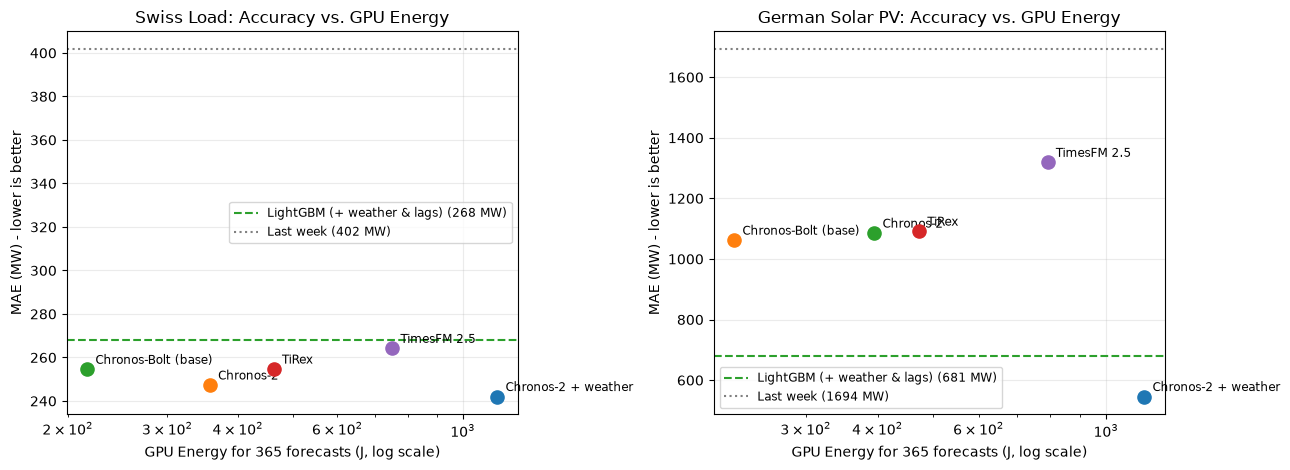

In [9]:
# Stress slices
aug_mask = ORIGINS.month == 8
cold_idx = np.argsort(regimes["Load"]["df"].loc["2019-01-01":"2019-12-31", "temperature"].resample("D").mean().values)[:10]
solar_ramp = np.mean(np.abs(np.diff(regimes["Solar"]["actual"], axis=1)), axis=1)
volatile_solar_idx = np.argsort(solar_ramp)[-20:]

stress_rows = []
for mname in preds["Load"]:
    p_l = preds["Load"][mname]
    p_s = np.clip(preds["Solar"][mname], 0.0, None)
    stress_rows.append({
        "Model": mname,
        "Load Aug MAE (MW)": mae(regimes["Load"]["actual"][aug_mask], p_l[aug_mask]),
        "Load 10-Coldest MAE (MW)": mae(regimes["Load"]["actual"][cold_idx], p_l[cold_idx]),
        "Solar Top-20 Ramp MAE (MW)": mae(regimes["Solar"]["actual"][volatile_solar_idx], p_s[volatile_solar_idx]),
    })
display(pd.DataFrame(stress_rows).set_index("Model").sort_values("Load Aug MAE (MW)").round(1))

# Pareto chart: MAE vs GPU Energy (for GPU foundation models; ML/naive shown as horizontal dashed lines)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, rname, res_df, title in [
    (axes[0], "Load", load_res, "Swiss Load: Accuracy vs. GPU Energy"),
    (axes[1], "Solar", solar_res, "German Solar PV: Accuracy vs. GPU Energy"),
]:
    gpu_sub = res_df.dropna(subset=["GPU Energy (J)"])
    for mname, row in gpu_sub.iterrows():
        ax.scatter(row["GPU Energy (J)"], row["MAE (MW)"], s=90, zorder=4)
        ax.annotate(mname, (row["GPU Energy (J)"], row["MAE (MW)"]), xytext=(6, 4), textcoords="offset points", fontsize=8.5)
    for base_name, color, ls in [("LightGBM (+ weather & lags)", "tab:green", "--"), ("Last week", "grey", ":")]:
        if base_name in res_df.index:
            ax.axhline(res_df.loc[base_name, "MAE (MW)"], color=color, linestyle=ls, lw=1.5, label=f"{base_name} ({res_df.loc[base_name, 'MAE (MW)']:.0f} MW)")
    ax.set_xscale("log")
    ax.set_xlabel("GPU Energy for 365 forecasts (J, log scale)")
    ax.set_ylabel("MAE (MW) - lower is better")
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8.5)

plt.tight_layout()
plt.savefig(IMG_DIR / "m1_benchmark_pareto.png", dpi=150, bbox_inches="tight")
plt.show()

**How to read the two regimes (and an honest leakage warning)**

1. **Univariate FMs shine on Load, but weather-aware models dominate Solar PV:**
   without future solar radiation, univariate FMs can only extrapolate recent daily bell curves and miss sudden cloudy days,
   whereas **Chronos-2 + weather** and trained **LightGBM + weather & lags** see the irradiance forecast directly.
2. **Pretraining overlap warning:** public OPSD / ENTSO-E data (2016–2020) overlaps with the pretraining window of several public TSFMs.
   Always test on post-cutoff internal utility meters alongside public benchmarks before claiming zero-shot superiority.

## 6. Operational, memory and energy summary

In [10]:
profiler.stop_run()
csv_path, json_path = profiler.save()
print(f"Saved step log to {csv_path.relative_to(ROOT)} and benchmark record to {json_path.relative_to(ROOT)}")

print("\n--- Model cards ---")
display(profiler.model_card_table())

print("\n--- Step-by-step operational profile ---")
display(profiler.summary_table())

print("\n--- Energy and CO2e summary (NVML GPU vs. CodeCarbon system) ---")
display(profiler.energy_summary_table())

Saved step log to data\cache\module1_timeseries_runtime.csv and benchmark record to benchmarks\results\module1_timeseries_02_tsfm_benchmark_energy.json

--- Model cards ---


,Params (M),Precision,Disk (MB),Peak VRAM (GB),Min Hardware,Licence,Limits
Model,,,,,,,
Ridge (+ weather & lags),NaN,cpu/sklearn,NaN,NaN,CPU-ok,BSD-3-Clause,Needs historical training split
LightGBM (+ weather & lags),NaN,cpu/sklearn,NaN,NaN,CPU-ok,MIT,Needs historical training split
Chronos-Bolt (base),205.29,float32,821.2,4.919,GPU <= 8 GB,Apache-2.0,"Context <= 2,048, univariate"
Chronos-2,119.48,float32,477.9,2.313,GPU <= 4 GB,Apache-2.0,Supports past & known-future covariates
TimesFM 2.5 (200M),231.29,float32,925.2,2.532,GPU <= 4 GB,Apache-2.0,Univariate core; covariates via xreg
TiRex,35.29,float32,141.2,0.300,GPU <= 4 GB,NX-AI Community / Apache-2.0 (check card),"Univariate, 9 deciles (0.1..0.9)"



--- Step-by-step operational profile ---


,Time (s),Peak VRAM (GB),Avg Power (W),GPU Energy (J),mJ / item,ms / item,CO2 CH (mg),CO2 EU (mg)
Step,,,,,,,,
1. Load OPSD load/solar and Open-Meteo weather,10.4,0.00,43.0,445.5,NaN,NaN,3.71,28.46
"2. Baselines (Last week, Ridge, LightGBM) on Load + Solar",108.4,0.00,23.9,2594.0,3553.37,148.54,21.62,165.72
3. Load Chronos-Bolt (base),2.4,0.82,24.1,56.7,NaN,NaN,0.47,3.62
4. Chronos-Bolt: Load 365 days,1.5,4.92,142.9,216.3,592.68,4.14,1.80,13.82
4. Chronos-Bolt: Solar 365 days,0.9,4.92,256.6,225.0,616.53,2.40,1.88,14.38
5. Load Chronos-2,1.4,0.49,74.3,102.1,NaN,NaN,0.85,6.52
6. Chronos-2 (univariate): Load,2.1,2.29,170.0,356.6,977.07,5.74,2.97,22.79
7. Chronos-2 + weather: Load,5.2,2.31,220.6,1150.7,3152.60,14.18,9.59,73.52
6. Chronos-2 (univariate): Solar,1.9,2.29,206.7,394.7,1081.49,5.22,3.29,25.22



--- Energy and CO2e summary (NVML GPU vs. CodeCarbon system) ---


,Duration (s),GPU (Wh),"CPU + RAM (Wh, modeled)",Total (Wh),CO2 CH 30g/kWh (mg),CO2 EU 230g/kWh (mg),CO2 US 380g/kWh (mg)
Scope,,,,,,,
"Profiled steps (GPU only, NVML 50 ms)",156.6,2.6181,NaN,2.6181,78.54,602.17,994.89
Whole notebook (CodeCarbon offline: GPU + CPU/RAM model),163.4,2.3009,11.5134,13.8143,414.43,3177.29,5249.43
